# 08 · Production: reclassified 30 m segments for any tile and year with SlideRule

Scales the method to our boreal tiles. One call of `ipl.process_tile(tile_geom, tile_num, year, cfg, out_dir)`:
1. looks up the ATL03 **v007** granules over the tile (CMR, June–September);
2. pulls all photons per granule from SlideRule (`atl03x`, with ATL08 v007 classes and ATL03 photon weights);
3. reclassifies the photons and builds 30 m segments (lib, config version recorded);
4. writes `atl08_reclass_007_030m_<year>_06_09_v<config>_<tile>.parquet` with provenance (git commit, config hash, granule
   list, SlideRule version) in the parquet metadata.

Output columns include those our filtering and covariate extraction use today (`h_canopy`, `rh25`…`rh98`, `h_te_median`,
`segment_landcover`, `segment_snowcover`, `msw_flag`, `solar_elevation`, `year`, `doy`, beam/strength) plus `short_veg_flag`,
`h_canopy_raw`, GEDI-style `rh*_gedi`, and photon rates `Ev`, `Eg` for canopy cover.

**Where to run.** MAAP ADE notebooks for tests; a DPS algorithm wrapping `process_tile` for all tiles (the photon volume per tile
is far larger than the segment volume; keep photon output off except for validation sites). Earlier SlideRule practice from
`icesat2_boreal/notebooks/tile_atl08_sliderule.ipynb` carries over: the `utexas` organisation for heavy runs, retries, and
truncating longitudes at the antimeridian.

The test below runs **one tile, one month** to measure run time and check the output.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.2.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.2 fc2468cc8841 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.2


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7e530f1",
 "git_dirty_lib_or_config": true,
 "config_version": "0.2",
 "config_sha1": "fc2468cc8841",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T18:39:47"
}


## Test: one tile, one month

**Input:** a tile polygon (default: the first Seward tile), year and months.

**What happens:** `process_tile` runs the whole chain for that tile: ATL03 v007 granule lookup → **ATL03 v007 photons with ATL08
v007 photon classes** (one SlideRule request per granule) → **reclassified photon classes (v0.1)** → **reclassified photons →
our 30 m (new)** → parquet with provenance. No reference data are involved: this is the production path.

**Output:** `production/atl08_reclass_007_030m_<year>_<months>_v0.1_<tile>.parquet`.

In [2]:
TEST_TILE, TEST_YEAR, TEST_MONTHS = None, 2024, [7]     # None: first Seward tile from notebook 00
OUT = RUN / "production"; OUT.mkdir(exist_ok=True)
tiles = gpd.read_file(cfg["paths"]["boreal_tiles"]).to_crs(4326)
tiles["tile_num"] = tiles.tile_num.astype(int)
if TEST_TILE is None:
    seward = gpd.read_parquet(WORK / "inventory" / "seward_sites.parquet")
    TEST_TILE = int(gpd.sjoin(tiles, seward[["geometry"]].dropna(), predicate="intersects").tile_num.iloc[0])
geom = tiles.set_index("tile_num").loc[TEST_TILE].geometry
# antimeridian: SlideRule needs |lon| <= 179.9999
print("tile", TEST_TILE, geom.bounds)
sliderule = ipl.sliderule_init()

tile 3638 (-166.1756276008608, 64.84902812660454, -163.83496294529945, 65.80241344492612)


In [3]:
import time
t0 = time.time()
segs, log = ipl.process_tile(geom, TEST_TILE, TEST_YEAR, cfg, OUT, months=TEST_MONTHS)
print(f"{len(segs):,} segments from {len(log)} granules ({log.n_photons.sum():,} photons) in {(time.time() - t0) / 60:.1f} min")
log

53,552 segments from 7 granules (23,928,507 photons) in 26.7 min


,granule,n_photons
0,ATL03_20240701223354_02212403_007_01.h5,9025985
1,ATL03_20240705222530_02822403_007_01.h5,7166670
2,ATL03_20240711103600_03662405_007_01.h5,34309
3,ATL03_20240715102749_04272405_007_01.h5,583253
4,ATL03_20240719101936_04882405_007_01.h5,264586
5,ATL03_20240726211801_06022403_007_01.h5,1655173
6,ATL03_20240730210938_06632403_007_01.h5,5198531


In [4]:
fn = sorted(OUT.glob(f"*_{TEST_TILE:07d}.parquet"))[-1]
print(fn.name); print(json.dumps({k: v for k, v in ipl.read_provenance(fn).items() if k != "granules"}, indent=1))
segs.drop(columns="geometry").describe().T[["count", "mean", "50%", "max"]].round(2).head(40)

atl08_reclass_007_030m_2024_07_07_v0.2_0003638.parquet
{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7e530f1",
 "git_dirty_lib_or_config": true,
 "config_version": "0.2",
 "config_sha1": "fc2468cc8841",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T19:06:27",
 "tile_num": 3638,
 "year": 2024,
 "months": [
  7
 ],
 "n_granules": 7
}


,count,mean,50%,max
seg,53552.0,307384.62,243600.00,427727.00
rgt,53552.0,450.07,427.00,663.00
cycle,53552.0,24.00,24.00,24.00
gt,53552.0,33.49,30.00,60.00
spot,53552.0,3.35,3.00,6.00
x_atc,53552.0,9221553.74,7308014.79,12831823.90
lon,53552.0,-165.06,-165.00,-163.93
lat,53552.0,65.30,65.29,65.80
lon0,53552.0,-165.06,-165.00,-163.93
lat0,53552.0,65.30,65.29,65.80


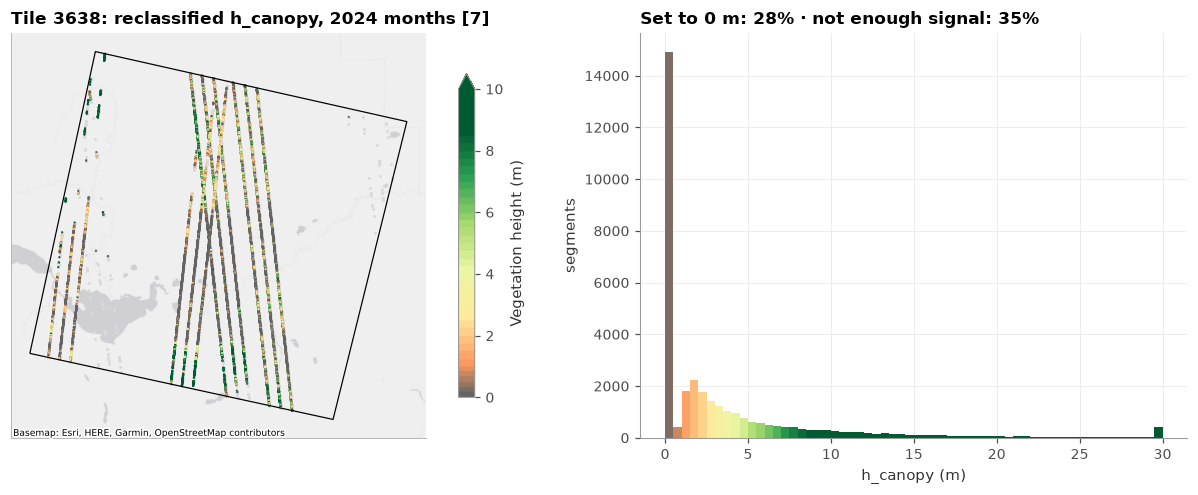

In [5]:
# Map: reclassified h_canopy on the ESRI Light Gray basemap, vegetation-height colormap (lib/plot_style.py)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
tiles[tiles.tile_num == TEST_TILE].to_crs(3857).boundary.plot(ax=axes[0], color="k", lw=0.8, zorder=4)
ps.plot_height_points(axes[0], segs, "h_canopy", crs=3857, markersize=2)
axes[0].set_title(f"Tile {TEST_TILE}: reclassified h_canopy, {TEST_YEAR} months {TEST_MONTHS}")
h = segs.h_canopy.dropna()
bins = np.arange(0, 30.5, 0.5)
n, edges, patches = axes[1].hist(h.clip(upper=30), bins=bins)
for p, x0 in zip(patches, edges[:-1]):          # bars in the same height colours as the map
    p.set_facecolor(ps.HEIGHT_CMAP(ps.height_norm()(x0 + 0.25)))
axes[1].set_xlabel("h_canopy (m)"); axes[1].set_ylabel("segments")
flag0 = segs.short_veg_flag.mean()
low = segs["low_signal"].mean() if "low_signal" in segs else np.nan
axes[1].set_title(f"Set to 0 m: {flag0:.0%} · not enough signal: {low:.0%}")
fig.tight_layout(); fig.savefig(FIG / "08_production_test.png")

## Batch loop (missing tiles), for a tile list × years

In [6]:
RUN_BATCH = False          # set True to process TILE_LIST x YEARS here; use DPS for the full domain
TILE_LIST, YEARS = [TEST_TILE], [2024]
def done(tile, year):
    return any(OUT.glob(f"atl08_reclass_*_{year}_06_09_v{cfg['version']}_{tile:07d}.parquet"))
if RUN_BATCH:
    for y in YEARS:
        for t in [t for t in TILE_LIST if not done(t, y)]:
            try:
                s, l = ipl.process_tile(tiles.set_index("tile_num").loc[t].geometry, t, y, cfg, OUT)
                print(t, y, len(s))
            except Exception as err:
                print(t, y, "failed:", err)
print("missing:", [(t, y) for y in YEARS for t in TILE_LIST if not done(t, y)])

missing: [(3638, 2024)]
